# 01 Data Analysis

#### Load the dataset Landslide4sense from Kaggle

In [3]:
import kagglehub
from pathlib import Path
import json

# Download latest version
path = kagglehub.dataset_download("tekbahadurkshetri/landslide4sense")


CACHE_FILE = Path(".dataset_path_cache.json")

def get_dataset_path():
    if CACHE_FILE.exists():
        cached_path = Path(json.loads(CACHE_FILE.read_text())["path"])
        if cached_path.exists():
            return cached_path

    path = Path(kagglehub.dataset_download("tekbahadurkshetri/landslide4sense"))
    CACHE_FILE.write_text(json.dumps({"path": str(path)}))
    return path

data_dir = get_dataset_path()


print("Path to dataset files:", data_dir)

Path to dataset files: /Users/katrinschmidt/.cache/kagglehub/datasets/tekbahadurkshetri/landslide4sense/versions/1


#### Count train/test/valid data samples

In [ ]:
sample_counts = {}
for split in ["TrainData", "ValidData", "TestData"]:
    n = len(list((data_dir / split / "img").glob("*.h5")))
    sample_counts[split] = n

total_samples = sum(sample_counts.values())
print(f"Total samples: {total_samples}\n")

for split, n in sample_counts.items():
    pct = n / total_samples * 100
    print(f"{split}: {n} samples ({pct:.1f}%)")

Total samples: 4844

TrainData: 3799 samples (78.4%)
ValidData: 245 samples (5.1%)
TestData: 800 samples (16.5%)


#### Visualize some data points:

- RGB bands (4, 3, 2) displayed in the left
- Mask containing the binary pixels (landslide vs. no landslide) in the middle
- Corresponding DEM on the right

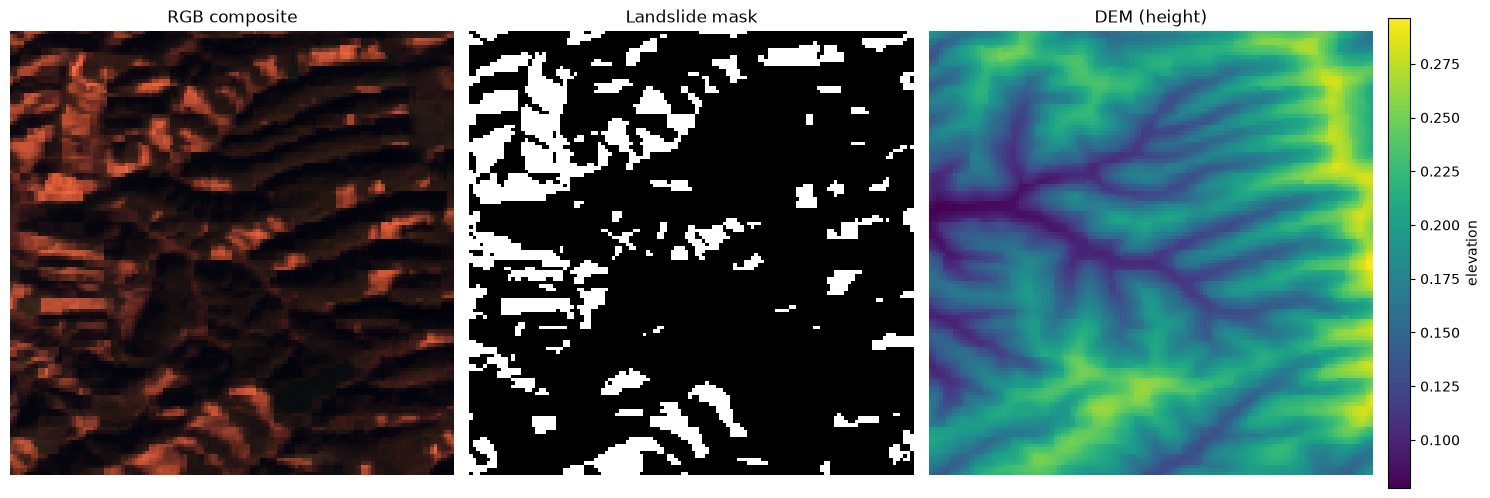

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import h5py

image_id = 3160  # <- set this to whichever sample you want

img_file = data_dir / "TrainData" / "img" / f"image_{image_id}.h5"
mask_file = data_dir / "TrainData" / "mask" / f"mask_{image_id}.h5"

with h5py.File(img_file, "r") as f:
    img = f["img"][:]

with h5py.File(mask_file, "r") as f:
    mask = f["mask"][:]

# Landslide4Sense bands: 1-12 = Sentinel-2, 13 = slope, 14 = DEM
# RGB composite ~ bands 4,3,2 (red, green, blue) -> zero-indexed 3,2,1
rgb = img[:, :, [3, 2, 1]]
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())  # normalize to [0,1] for display
dem = img[:,:,-1]


fig, axes = plt.subplots(1, 4, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1, 1, 0.05]})

# RGB
axes[0].imshow(rgb)
axes[0].set_title("RGB composite")
axes[0].axis("off")

# Mask
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Landslide mask")
axes[1].axis("off")

# DEM
dem_im = axes[2].imshow(dem)
axes[2].set_title("DEM (height)")
axes[2].axis("off")

fig.colorbar(dem_im, cax=axes[3], label="elevation")

plt.tight_layout()
plt.show()

# TODO: Check if VNIR or TIR/LWIR are part of the spectral bands

#### Investigation of the mask

In [ ]:
# Investigate the landslide pixels within the mask

print("unique values:", np.unique(mask))
print("landslide pixels:", mask.sum(), "/", mask.size)


unique values: [0 1]
landslide pixels: 3040 / 16384


In [30]:
# Which mask has landslides, which doesn't?

mask_dir = data_dir / "TrainData" / "mask"

with_landslide = []
without_landslide = []

for mask_file in mask_dir.glob("*.h5"):
    with h5py.File(mask_file, "r") as f:
        m = f["mask"][:]
    if m.sum() > 0:
        with_landslide.append(mask_file.name)
    else:
        without_landslide.append(mask_file.name)

total = len(with_landslide) + len(without_landslide)
print(f"With landslide:    {len(with_landslide)} ({len(with_landslide) / total * 100:.1f}%)")
print(f"Without landslide: {len(without_landslide)} ({len(without_landslide) / total * 100:.1f}%)")


With landslide:    2231 (58.7%)
Without landslide: 1568 (41.3%)


#### Pixel-level class imbalance

Amount of all landslide vs. not landslide pixels across the training set

In [ ]:
total_pixels = 0
landslide_pixels = 0

for mask_file in mask_dir.glob("*.h5"):
    with h5py.File(mask_file, "r") as f:
        m = f["mask"][:]
    total_pixels += m.size
    landslide_pixels += int(m.sum())

non_landslide_pixels = total_pixels - landslide_pixels
print(f"Landslide pixels:     {landslide_pixels} ({landslide_pixels / total_pixels * 100:.2f}%)")
print(f"Non-landslide pixels: {non_landslide_pixels} ({non_landslide_pixels / total_pixels * 100:.2f}%)")

# TODO: Take imbalance into consideration for loss function!

Landslide pixels:     1442790 (2.32%)
Non-landslide pixels: 60800026 (97.68%)


#### Per-band statistics

* Min/max/mean/std for each of the 14 bands across the whole training set 
* Useful to check if bands are on very different scales (reflectance vs. slope/DEM) and need separate normalization.
* Finding: seems like they are already normalized

In [38]:
n_bands = 14
band_min = np.full(n_bands, np.inf)
band_max = np.full(n_bands, -np.inf)
band_sum = np.zeros(n_bands)
band_sumsq = np.zeros(n_bands)
n_pixels = 0

img_dir = data_dir / "TrainData" / "img"

for img_file in img_dir.glob("*.h5"):
    with h5py.File(img_file, "r") as f:
        arr = f["img"][:]  # (128, 128, 14)
    band_min = np.minimum(band_min, arr.min(axis=(0, 1)))
    band_max = np.maximum(band_max, arr.max(axis=(0, 1)))
    band_sum += arr.sum(axis=(0, 1))
    band_sumsq += (arr ** 2).sum(axis=(0, 1))
    n_pixels += arr.shape[0] * arr.shape[1]

band_mean = band_sum / n_pixels
band_std = np.sqrt(band_sumsq / n_pixels - band_mean ** 2)

for b in range(n_bands):
    print(f"Band {b + 1:2d}: min={band_min[b]:10.3f}  max={band_max[b]:10.3f}  mean={band_mean[b]:10.3f}  std={band_std[b]:10.3f}")

Band  1: min=     0.000  max=     3.106  mean=     0.926  std=     0.141
Band  2: min=     0.000  max=    19.762  mean=     0.923  std=     0.221
Band  3: min=     0.000  max=    31.552  mean=     0.954  std=     0.318
Band  4: min=     0.000  max=    33.160  mean=     0.960  std=     0.572
Band  5: min=     0.000  max=     9.973  mean=     1.023  std=     0.460
Band  6: min=     0.000  max=     4.144  mean=     1.043  std=     0.447
Band  7: min=     0.000  max=     3.693  mean=     1.036  std=     0.465
Band  8: min=     0.000  max=     8.313  mean=     1.047  std=     0.495
Band  9: min=     0.000  max=     3.549  mean=     1.170  std=     0.513
Band 10: min=     0.000  max=    21.442  mean=     1.174  std=     0.684
Band 11: min=     0.000  max=     5.786  mean=     1.049  std=     0.532
Band 12: min=     0.000  max=    19.661  mean=     1.037  std=     0.663
Band 13: min=     0.000  max=     4.041  mean=     1.251  std=     0.678
Band 14: min=     0.000  max=     5.121  mean=     